# Example of the aitlas toolbox in the context of object detection

## Import the required packages

In [ ]:
from aitlas.datasets import SearchAndRescueDataset
from aitlas.models import FasterRCNN
from aitlas.transforms import Resize
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/search_and_rescue/dataset/train/",
    "annotation_dir": "./data/search_and_rescue/dataset/annotations/train.json",
}
dataset = SearchAndRescueDataset(dataset_config)
print(f"Total number of patches: {len(dataset)}")

Total number of patches: 1808


## Show images with bounding boxes

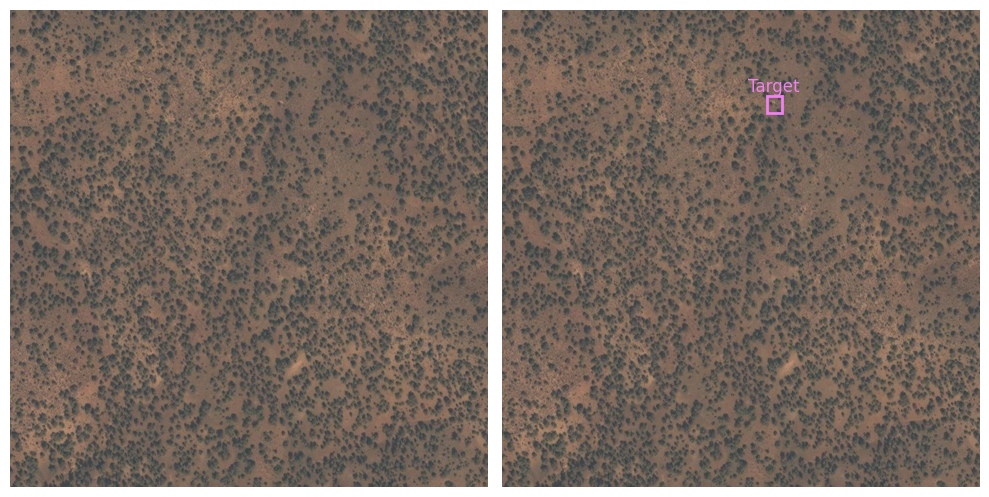

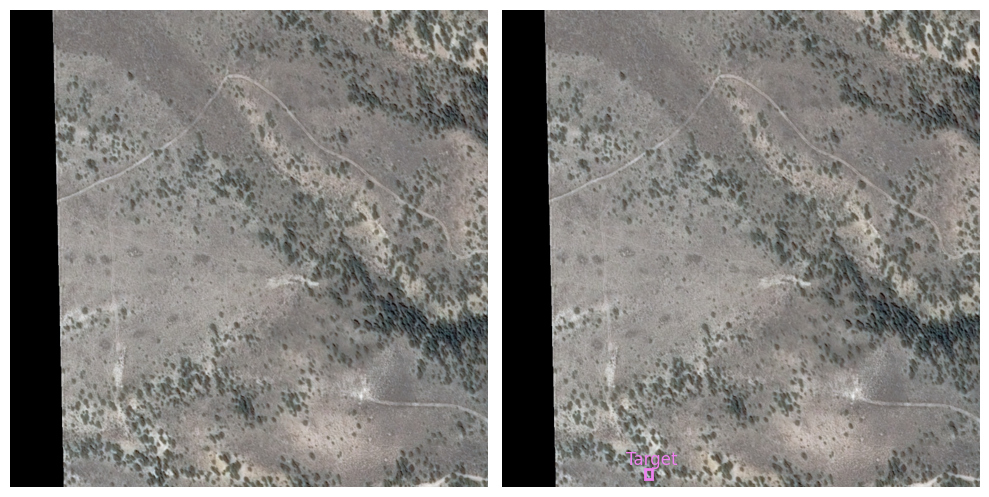

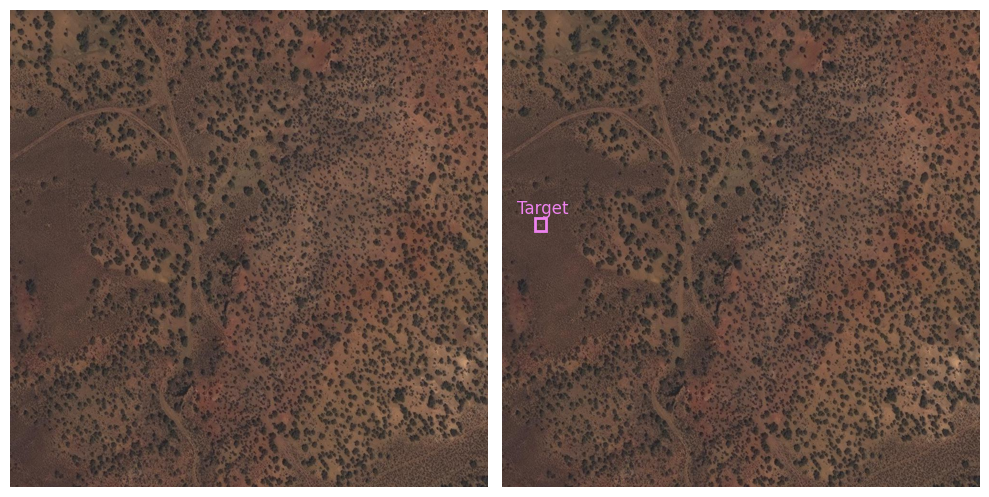

In [34]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(100)
fig3 = dataset.show_image(500);

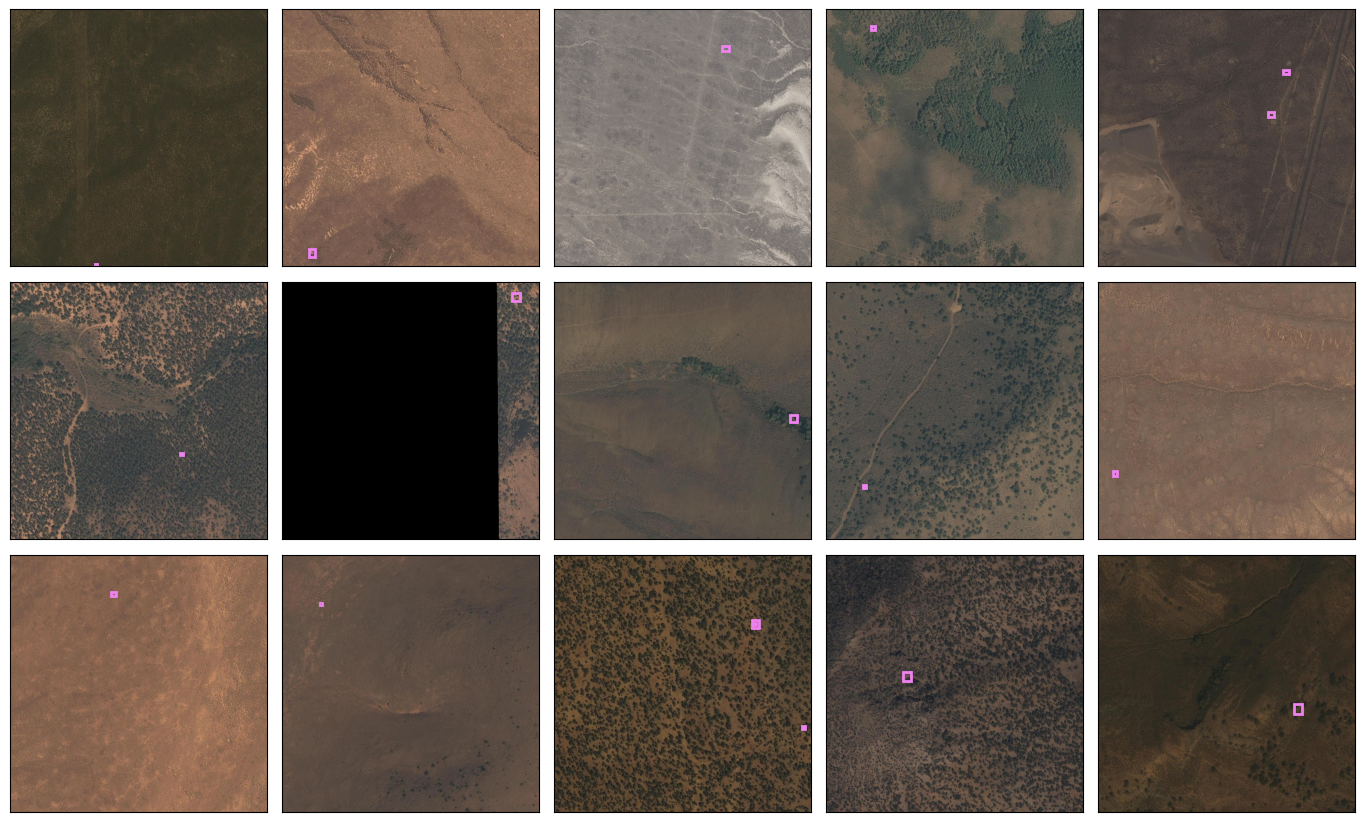

In [35]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [58]:
dataset.data_distribution_table()

,Label,Count
0,Target,3048


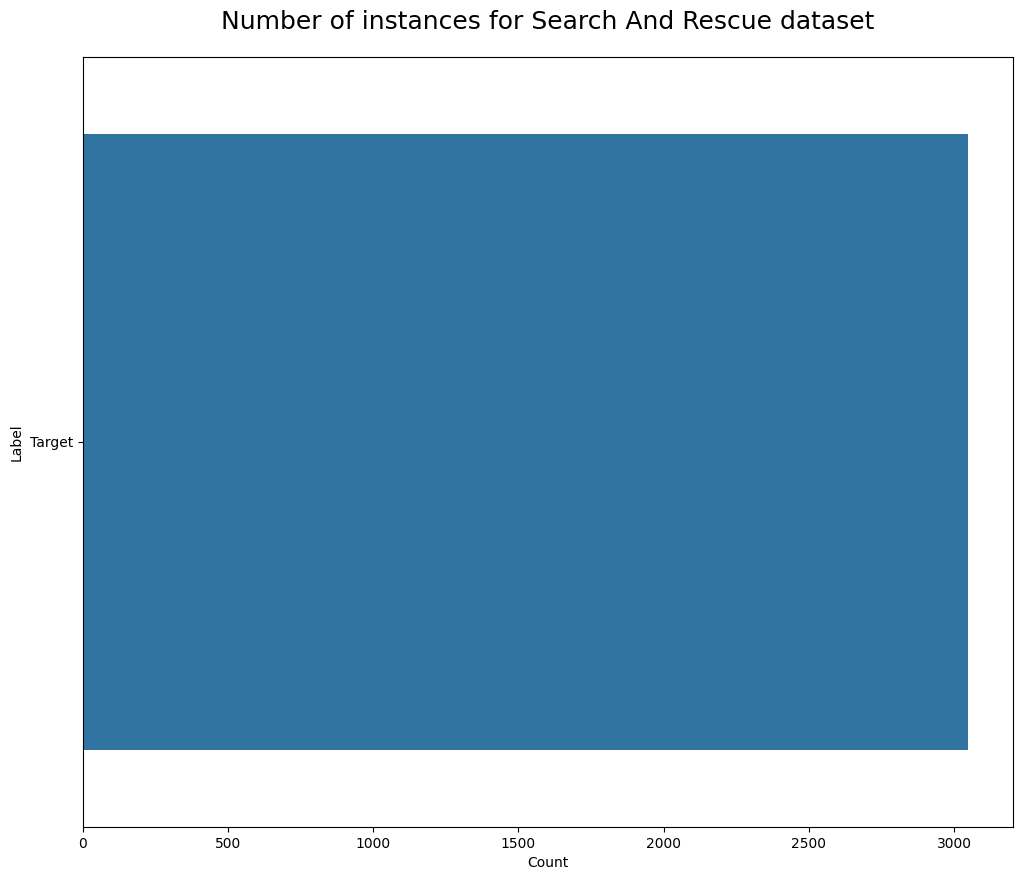

In [59]:
fig = dataset.data_distribution_barchart()

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/search_and_rescue/dataset/train/", 
    "annotation_dir": "./data/search_and_rescue/dataset/annotations/train.json",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = SearchAndRescueDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 1808


## Setup and create the model for training

In [ ]:
epochs = 20
model_directory = "./data/experiments/search_and_rescue"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Training

In [70]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-10 14:15:05,398 INFO Starting training.
training: 100%|██████████| 226/226 [01:12<00:00,  3.10it/s]
2025-11-10 14:16:18,353 INFO epoch: 1, time: 73, loss:  0.45259
testing on train set: 100%|██████████| 226/226 [00:39<00:00,  5.76it/s]
2025-11-10 14:17:02,545 INFO map:0.013587521389126778, map_50:0.0521920770406723, map_75:0.0024735135957598686, map_small:0.013587785884737968, map_medium:-1.0, map_large:-1.0, mar_1:0.039730969816446304, mar_10:0.09288057684898376, mar_100:0.10603674501180649, mar_small:0.10603674501180649, mar_medium:-1.0, mar_large:-1.0, map_per_class:0.013587521389126778, mar_100_per_class:0.10603674501180649, classes:1.0
training: 100%|██████████| 226/226 [01:14<00:00,  3.03it/s]
2025-11-10 14:18:17,139 INFO epoch: 2, time: 75, loss:  0.30375
testing on train set: 100%|██████████| 226/226 [00:38<00:00,  5.91it/s]
2025-11-10 14:18:59,056 INFO map:0.020447159186005592, map_50:0.07159488648176193, map_75:0.005868916399776936, map_small:0.02044752985239029, map_

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/search_and_rescue/dataset/val/", 
    "annotation_dir": "./data/search_and_rescue/dataset/annotations/val.json",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = SearchAndRescueDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/search_and_rescue/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 490


2025-11-10 15:11:05,130 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/search_and_rescue/checkpoint.pth.tar
2025-11-10 15:11:05,485 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/search_and_rescue/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 62/62 [00:12<00:00,  5.10it/s]


[{'map': 0.009140427224338055,
  'map_50': 0.03192896768450737,
  'map_75': 0.0012310495367273688,
  'map_small': 0.009140427224338055,
  'map_medium': -1.0,
  'map_large': -1.0,
  'mar_1': 0.021954484283924103,
  'mar_10': 0.04457831382751465,
  'mar_100': 0.04524765908718109,
  'mar_small': 0.04524765908718109,
  'mar_medium': -1.0,
  'mar_large': -1.0,
  'map_per_class': 0.009140427224338055,
  'mar_100_per_class': 0.04524765908718109,
  'classes': 1.0}]

## Predictions

2025-11-10 15:11:18,626 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/search_and_rescue/checkpoint.pth.tar
2025-11-10 15:11:18,982 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/search_and_rescue/checkpoint.pth.tar at epoch 21


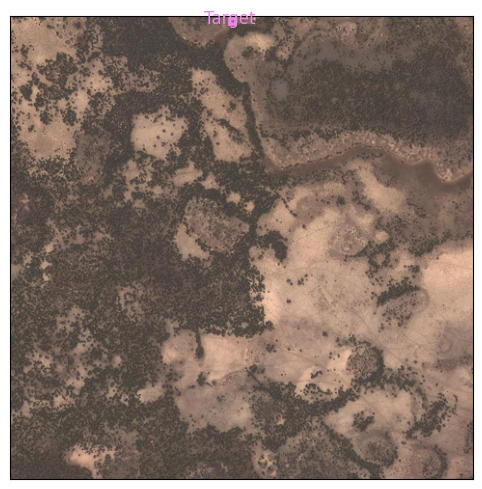

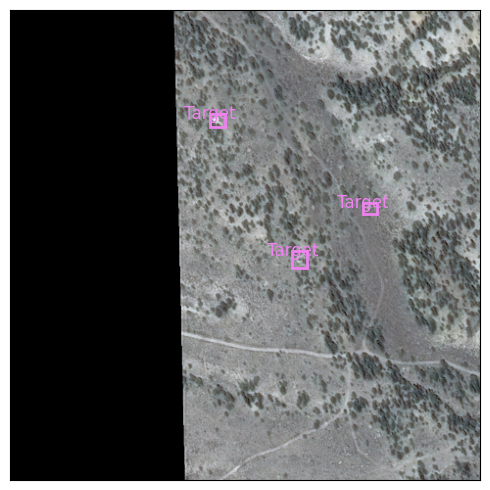

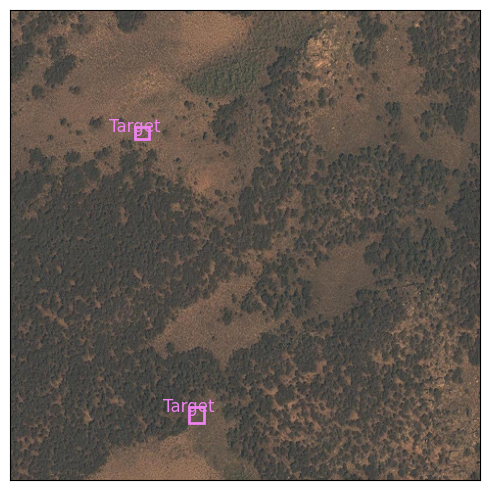

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/search_and_rescue/checkpoint.pth.tar"
labels = ["No-data", "Target"]
transform = Resize()
model.load_model(model_path)

image = image_loader("./data/search_and_rescue/dataset/test/000609.jpg")
fig = model.detect_objects(image, labels, transform)

image = image_loader("./data/search_and_rescue/dataset/test/018051.jpg")
fig = model.detect_objects(image, labels, transform)

image = image_loader("./data/search_and_rescue/dataset/test/046854.jpg")
fig = model.detect_objects(image, labels, transform)